# 🍌 MusaVision: Audit Data & Eksperimen Deteksi Penyakit Daun Pisang (Revisi)
**Peneliti:** Muh Bintang Mahardani (UBSI)  
**Dosen Pembimbing:** Bpk. Ibnu Rusdi  

### 📌 Tujuan Eksekusi (Menjawab 5 Poin Catatan Pembimbing):
1. **Audit Resolusi & Granularitas:** Membuktikan bahwa ukuran *bounding box* tidak seragam (mencegah salah kaprah "hitung lesi") dan memeriksa korelasi resolusi (224 vs 640) terhadap kelas.
2. **Pembersihan Kebocoran Data (Data Leakage):** Melakukan deduplikasi gambar dengan metode *Perceptual Hash* (dHash) ambang batas $\le 3$ bit, serta menghapus 709 file augmentasi hulu (`_aug`).
3. **Karantina Label Anomali:** Menemukan dan membuang 93 gambar berawalan `black-` yang secara keliru berlabel *Yellow Sigatoka*.
4. **Studi Ablasi Terkontrol:** Menguji YOLOv8n, YOLO11n, YOLO26n (Tanpa CLAHE), dan YOLO26n (+ LAB-CLAHE kanal Luminans) dengan protokol sama (50 epoch, resolusi seragam 640x640).
5. **Analisis AP Per-Kelas & Kemiripan Visual:** Menampilkan *Confusion Matrix* dan metrik kelas untuk membuktikan tantangan deteksi pada penyakit yang mirip secara visual (contoh: *Pestalotiopsis*).


---
### TAHAP 1: Audit Lengkap Forensik Dataset Awal

In [5]:
# ==============================================================================
# TAHAP 1: INSTALASI LIBRARY & AUDIT LENGKAP FORENSIK DATASET KAGGLE
# ==============================================================================
!pip install -q ultralytics

import time
import os
import re
import cv2
import yaml
import shutil
import random
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm import tqdm
from ultralytics import YOLO
from IPython.display import Image, display, FileLink, HTML

# 1. Kunci Random Seed agar eksperimen 100% dapat direproduksi
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("="*70)
print("🔍 TAHAP 1: MEMBACA DAN MENGAUDIT DATASET SUMBER")
print("="*70)

# 2. Mencari dataset otomatis
RAW_DATA_DIR = None
for root, dirs, files in os.walk('/kaggle/input'):
    if 'data.yaml' in files:
        RAW_DATA_DIR = Path(root)
        break

assert RAW_DATA_DIR is not None, "Dataset data.yaml tidak ditemukan!"
print(f"[INFO] Path Dataset: {RAW_DATA_DIR}")

with open(RAW_DATA_DIR / 'data.yaml', 'r') as f:
    CLASS_NAMES = yaml.safe_load(f)['names']
print(f"[INFO] Kelas Penyakit (5): {CLASS_NAMES}\n")

records = []
for split in ['train', 'valid', 'test']:
    img_dir = RAW_DATA_DIR / split / 'images'
    lbl_dir = RAW_DATA_DIR / split / 'labels'
    if not img_dir.exists(): continue
    
    img_paths = list(img_dir.glob('*.*'))
    
    for img_path in tqdm(img_paths, desc=f"Menganalisis split '{split}'"):
        lbl_path = lbl_dir / f"{img_path.stem}.txt"
        if not lbl_path.exists(): continue
        
        # Ekstrak resolusi
        img = cv2.imread(str(img_path))
        if img is None: continue
        h, w = img.shape[:2]
        
        fname = img_path.name
        is_aug = '_aug' in fname
        
        if fname.startswith('black-'): prefix = 'black-'
        elif fname.startswith('fresh-'): prefix = 'fresh-'
        elif fname.startswith('yellow-'): prefix = 'yellow-'
        elif fname.startswith('Banana-Cordana-'): prefix = 'Banana-Cordana-'
        elif fname.startswith('Banana-Pestalotiopsis-'): prefix = 'Banana-Pestalotiopsis-'
        else: prefix = 'numeric'
            
        # Analisis Bounding Box
        with open(lbl_path, 'r') as lf:
            lines = [line.strip().split() for line in lf.readlines() if len(line.strip().split()) >= 5]
        if not lines: continue
            
        classes_in_img = [int(l[0]) for l in lines]
        box_areas = [float(l[3]) * float(l[4]) for l in lines] 
        
        records.append({
            'split_orig': split, 'img_path': str(img_path), 'lbl_path': str(lbl_path),
            'filename': fname, 'prefix': prefix, 'is_aug': is_aug,
            'resolution': f"{w}x{h}", 'primary_class': CLASS_NAMES[classes_in_img[0]],
            'box_areas': box_areas
        })

df_audit = pd.DataFrame(records)

print("\n" + "="*70)
print("📊 LAPORAN HASIL AUDIT DATASET (Sesuai Catatan Dosen)")
print("="*70)

print(f"\n[HASIL AUDIT 1] Total Seluruh Gambar Valid Terbaca: {len(df_audit)} file")

print(f"\n[HASIL AUDIT 2] Temuan File Augmentasi Hulu (_aug): {df_audit['is_aug'].sum()} file (Terindikasi Bocor Antar-Split)")
print(df_audit.groupby(['split_orig', 'is_aug']).size().unstack(fill_value=0))

print("\n[HASIL AUDIT 3] Korelasi Resolusi vs Kelas (Risiko Shortcut):")
print(pd.crosstab(df_audit['primary_class'], df_audit['resolution'], margins=True))

print("\n[HASIL AUDIT 4] Granularitas Anotasi (Median Luas Bounding Box % per Kelas):")
all_boxes = []
for _, row in df_audit.iterrows():
    for area in row['box_areas']:
        all_boxes.append({'Kelas': row['primary_class'], 'Area_Pct': area * 100.0})
print(pd.DataFrame(all_boxes).groupby('Kelas')['Area_Pct'].agg(['count', 'median', 'mean']).round(2))

anomali_black = df_audit[(df_audit['prefix'] == 'black-') & (df_audit['primary_class'] == 'Yellow Sigatoka')]
print(f"\n[HASIL AUDIT 5] Ditemukan {len(anomali_black)} file anomali (Nama 'black-' tetapi berlabel 'Yellow Sigatoka')")

🔍 TAHAP 1: MEMBACA DAN MENGAUDIT DATASET SUMBER
[INFO] Path Dataset: /kaggle/input/datasets/bintangmahardani/diseasebanana/Banana Leaf Disease Detection.v1i.yolov8
[INFO] Kelas Penyakit (5): ['Black Sigatoka', 'Cordana', 'Fresh', 'Pestalotiopsis', 'Yellow Sigatoka']



Menganalisis split 'test': 100%|██████████| 641/641 [00:02<00:00, 307.62it/s]



📊 LAPORAN HASIL AUDIT DATASET (Sesuai Catatan Dosen)

[HASIL AUDIT 1] Total Seluruh Gambar Valid Terbaca: 6415 file

[HASIL AUDIT 2] Temuan File Augmentasi Hulu (_aug): 709 file (Terindikasi Bocor Antar-Split)
is_aug      False  True 
split_orig              
test          561     80
train        3993    498
valid        1152    131

[HASIL AUDIT 3] Korelasi Resolusi vs Kelas (Risiko Shortcut):
resolution       224x224  640x640   All
primary_class                          
Black Sigatoka         0     1417  1417
Cordana              789      314  1103
Fresh                  0     1419  1419
Pestalotiopsis       710      298  1008
Yellow Sigatoka        0     1468  1468
All                 1499     4916  6415

[HASIL AUDIT 4] Granularitas Anotasi (Median Luas Bounding Box % per Kelas):
                 count  median   mean
Kelas                                
Black Sigatoka    2622   13.40  19.95
Cordana           2450   11.37  24.61
Fresh             1420   79.41  75.12
Pestalotiopsi

---
### TAHAP 2: Pembersihan Kebocoran Data & Pembuatan Dataset LAB-CLAHE
Langkah ini secara berurutan membuang file augmentasi hulu, mengkarantina anomali label, menghapus gambar duplikat (*dHash*), merekonstruksi rasio split 70:20:10 yang bersih, serta menerapkan pemerataan resolusi 640x640 dan pra-pemrosesan **LAB-CLAHE** secara massal.

In [2]:
# ==============================================================================
# TAHAP 2: DEDUPLIKASI dHASH, RESPLIT, & PEMBANGUNAN DATASET BERSIH
# ==============================================================================
print("="*70)
print("🧹 TAHAP 2: PROSES PEMBERSIHAN DATA (DATA HYGIENE)")
print("="*70)

def compute_dhash(img_path, hash_size=8):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    resized = cv2.resize(img, (hash_size + 1, hash_size))
    diff = resized[:, 1:] > resized[:, :-1]
    return int(''.join(['1' if b else '0' for b in diff.flatten()]), 2)

df_audit['dhash'] = [compute_dhash(p) for p in tqdm(df_audit['img_path'], desc="Menghitung dHash 64-bit")]

# 1. Buang file augmentasi bawaan (_aug) dan label anomali
df_clean = df_audit[~df_audit['is_aug']].copy()
df_clean = df_clean[~((df_clean['prefix'] == 'black-') & (df_clean['primary_class'] == 'Yellow Sigatoka'))]
print(f"\n[CLEANING 1] Menghapus file augmentasi dan anomali label. Sisa gambar murni: {len(df_clean)}")

# 2. Hapus duplikat visual (Selisih dHash <= 3 bit)
keep_idx, kept_hashes = [], []
for idx, h in enumerate(df_clean['dhash']):
    if not any(bin(h ^ kh).count('1') <= 3 for kh in kept_hashes):
        keep_idx.append(idx)
        kept_hashes.append(h)

df_dedup = df_clean.iloc[keep_idx].reset_index(drop=True)
print(f"[CLEANING 2] Menghapus duplikat gambar identik (dHash <= 3 bit). Sisa akhir: {len(df_dedup)}")

# 3. Re-Split Stratified (70:20:10)
from sklearn.model_selection import train_test_split
dfs_train, dfs_valid, dfs_test = [], [], []
for _, group in df_dedup.groupby('primary_class'):
    tr, temp = train_test_split(group, test_size=0.30, random_state=SEED)
    va, te = train_test_split(temp, test_size=0.3333, random_state=SEED)
    dfs_train.append(tr.assign(new_split='train'))
    dfs_valid.append(va.assign(new_split='valid'))
    dfs_test.append(te.assign(new_split='test'))
df_final = pd.concat(dfs_train + dfs_valid + dfs_test).reset_index(drop=True)

print("\n[HASIL RE-SPLIT] Distribusi Dataset Baru Bebas-Bocor (70:20:10):")
print(pd.crosstab(df_final['primary_class'], df_final['new_split'], margins=True))

# 4. Bangun Dataset (Raw 640 & LAB-CLAHE 640)
DIR_RAW = Path('/kaggle/working/data_raw')
DIR_CLAHE = Path('/kaggle/working/data_clahe')
clahe_op = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def build_dataset(df, target_dir, apply_clahe=False):
    if target_dir.exists(): shutil.rmtree(target_dir)
    for sp in ['train', 'valid', 'test']:
        (target_dir / sp / 'images').mkdir(parents=True, exist_ok=True)
        (target_dir / sp / 'labels').mkdir(parents=True, exist_ok=True)
        
    desc_str = f"Membangun LAB-CLAHE 640x640" if apply_clahe else f"Membangun RAW 640x640"
    for _, row in tqdm(df.iterrows(), total=len(df), desc=desc_str):
        img = cv2.resize(cv2.imread(row['img_path']), (640, 640))
        if apply_clahe:
            lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
            l, a, b = cv2.split(lab)
            img = cv2.cvtColor(cv2.merge((clahe_op.apply(l), a, b)), cv2.COLOR_LAB2BGR)
            
        cv2.imwrite(str(target_dir / row['new_split'] / 'images' / row['filename']), img)
        shutil.copyfile(row['lbl_path'], str(target_dir / row['new_split'] / 'labels' / f"{Path(row['filename']).stem}.txt"))
        
    yaml_dict = {'path': str(target_dir), 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'nc': len(CLASS_NAMES), 'names': CLASS_NAMES}
    with open(target_dir / 'data.yaml', 'w') as f: yaml.dump(yaml_dict, f, sort_keys=False)

print("\n⚙️ Mengekspor gambar ke /kaggle/working ...")
build_dataset(df_final, DIR_RAW, apply_clahe=False)
build_dataset(df_final, DIR_CLAHE, apply_clahe=True)
print("[SUKSES] Dataset Clean-Raw dan Clean-LAB-CLAHE siap untuk Training!")

🧹 TAHAP 2: PROSES PEMBERSIHAN DATA (DATA HYGIENE)


Menghitung dHash 64-bit: 100%|██████████| 6415/6415 [00:12<00:00, 510.43it/s]



[CLEANING 1] Menghapus file augmentasi dan anomali label. Sisa gambar murni: 5613
[CLEANING 2] Menghapus duplikat gambar identik (dHash <= 3 bit). Sisa akhir: 5400

[HASIL RE-SPLIT] Distribusi Dataset Baru Bebas-Bocor (70:20:10):
new_split        test  train  valid   All
primary_class                            
Black Sigatoka    142    990    283  1415
Cordana            62    434    124   620
Fresh             141    984    282  1407
Pestalotiopsis     60    418    120   598
Yellow Sigatoka   136    952    272  1360
All               541   3778   1081  5400

⚙️ Mengekspor gambar ke /kaggle/working ...


Membangun LAB-CLAHE 640x640: 100%|██████████| 5400/5400 [01:30<00:00, 59.50it/s]

[SUKSES] Dataset Clean-Raw dan Clean-LAB-CLAHE siap untuk Training!


---
### TAHAP 3: Studi Ablasi Komparatif (Training Terkontrol)
Melatih 4 skenario arsitektur dengan menggunakan parameter seragam (50 Epochs, imgsz=640, batch=16) untuk menguji dampak implementasi algoritma LAB-CLAHE pada YOLO generasi terbaru (YOLO26 Nano). Catatan: *Ultralytics YOLO secara native menangani ketidakseimbangan kelas moderat lewat optimasi BCE Loss, sehingga kita akan mengevaluasi AP per kelas di tahap selanjutnya.*

In [3]:
# ==============================================================================
# TAHAP 3: STUDI ABLASI PELATIHAN YOLO (v8n, v11n, v26n, v26n+CLAHE)
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

EXPERIMENTS = [
    {'name': '1_YOLOv8n_Raw', 'weights': 'yolov8n.pt', 'data': str(DIR_RAW/'data.yaml')},
    {'name': '2_YOLO11n_Raw', 'weights': 'yolo11n.pt', 'data': str(DIR_RAW/'data.yaml')},
    {'name': '3_YOLO26n_Raw', 'weights': 'yolo26n.pt', 'data': str(DIR_RAW/'data.yaml')},
    {'name': '4_YOLO26n_LAB_CLAHE', 'weights': 'yolo26n.pt', 'data': str(DIR_CLAHE/'data.yaml')}
]

trained_models = {}

print("="*70)
print("🚀 TAHAP 3: MEMULAI TRAINING 4 SKENARIO MODEL (50 EPOCHS)")
print("="*70)

for exp in EXPERIMENTS:
    print(f"\n[TRAINING] Sedang melatih arsitektur: {exp['name']} ...")
    model = YOLO(exp['weights'])
    
    # Mode Verbose=False agar log tidak menuh-menuhin layar, hasil akhir akan ditarik di Tahap 4
    model.train(
        data=exp['data'], 
        epochs=50, 
        imgsz=640, 
        batch=16, 
        project='/kaggle/working/runs', 
        name=exp['name'], 
        seed=SEED, 
        deterministic=True, 
        verbose=False
    )
    trained_models[exp['name']] = f"/kaggle/working/runs/{exp['name']}/weights/best.pt"
    print(f"✅ Selesai: {exp['name']} -> Bobot tersimpan di runs/{exp['name']}/weights/best.pt")

print("\n[SUKSES] Seluruh skenario training selesai!")

🚀 TAHAP 3: MEMULAI TRAINING 4 SKENARIO MODEL (50 EPOCHS)

[TRAINING] Sedang melatih arsitektur: 1_YOLOv8n_Raw ...
Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data_raw/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yol

---
### TAHAP 4: Ekstraksi Tabel Komparasi, AP Per Kelas, dan Menampilkan Grafik Otomatis
Tahap ini mencetak tabel detail metrik evaluasi model (Precision, Recall, mAP) pada split Test, tabel Average Precision (AP) per kelas untuk membuktikan hipotesis kemiripan visual pada *Pestalotiopsis* dan *Black Sigatoka*, serta langsung memunculkan gambar **Confusion Matrix** tanpa harus men-download.

📊 TAHAP 4: HASIL EVALUASI UJI DAN ANALISIS VISUAL
[PROSES] Mengekstraksi metrik pada data TEST...
Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1898.8±544.6 MB/s, size: 68.4 KB)
val: Scanning /kaggle/working/data_raw/test/labels.cache... 541 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 541/541 55.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 34/34 5.7it/s 6.0s0.1s
                   all        541       1039      0.826      0.787      0.833      0.627
Speed: 1.5ms preprocess, 4.9ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-5
Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GF

,Skenario Arsitektur,Precision (%),Recall (%),mAP@50 (%),mAP@50-95 (%)
0,1_YOLOv8n_Raw,82.62,78.73,83.27,62.67
1,2_YOLO11n_Raw,81.41,79.31,83.10,62.96
2,3_YOLO26n_Raw,83.73,80.55,84.72,64.06
3,4_YOLO26n_LAB_CLAHE,84.09,78.92,84.20,63.91



📌 TABEL 2: RINCIAN AP PER KELAS PADA MODEL TERBAIK (Membuktikan kesulitan lokalisasi Pestalotiopsis)


,Kelas Penyakit,Precision (%),Recall (%),AP@50 (%)
0,Black Sigatoka,78.07,65.94,72.54
1,Cordana,87.75,86.67,92.87
2,Fresh,99.56,100.00,99.50
3,Pestalotiopsis,67.98,54.91,64.48
4,Yellow Sigatoka,87.09,87.07,91.63



🖼️ MENAMPILKAN GAMBAR HASIL EVALUASI (YOLO26n + LAB-CLAHE)

👉 1. CONFUSION MATRIX (Bukti Kemiripan Visual Black vs Yellow Sigatoka)


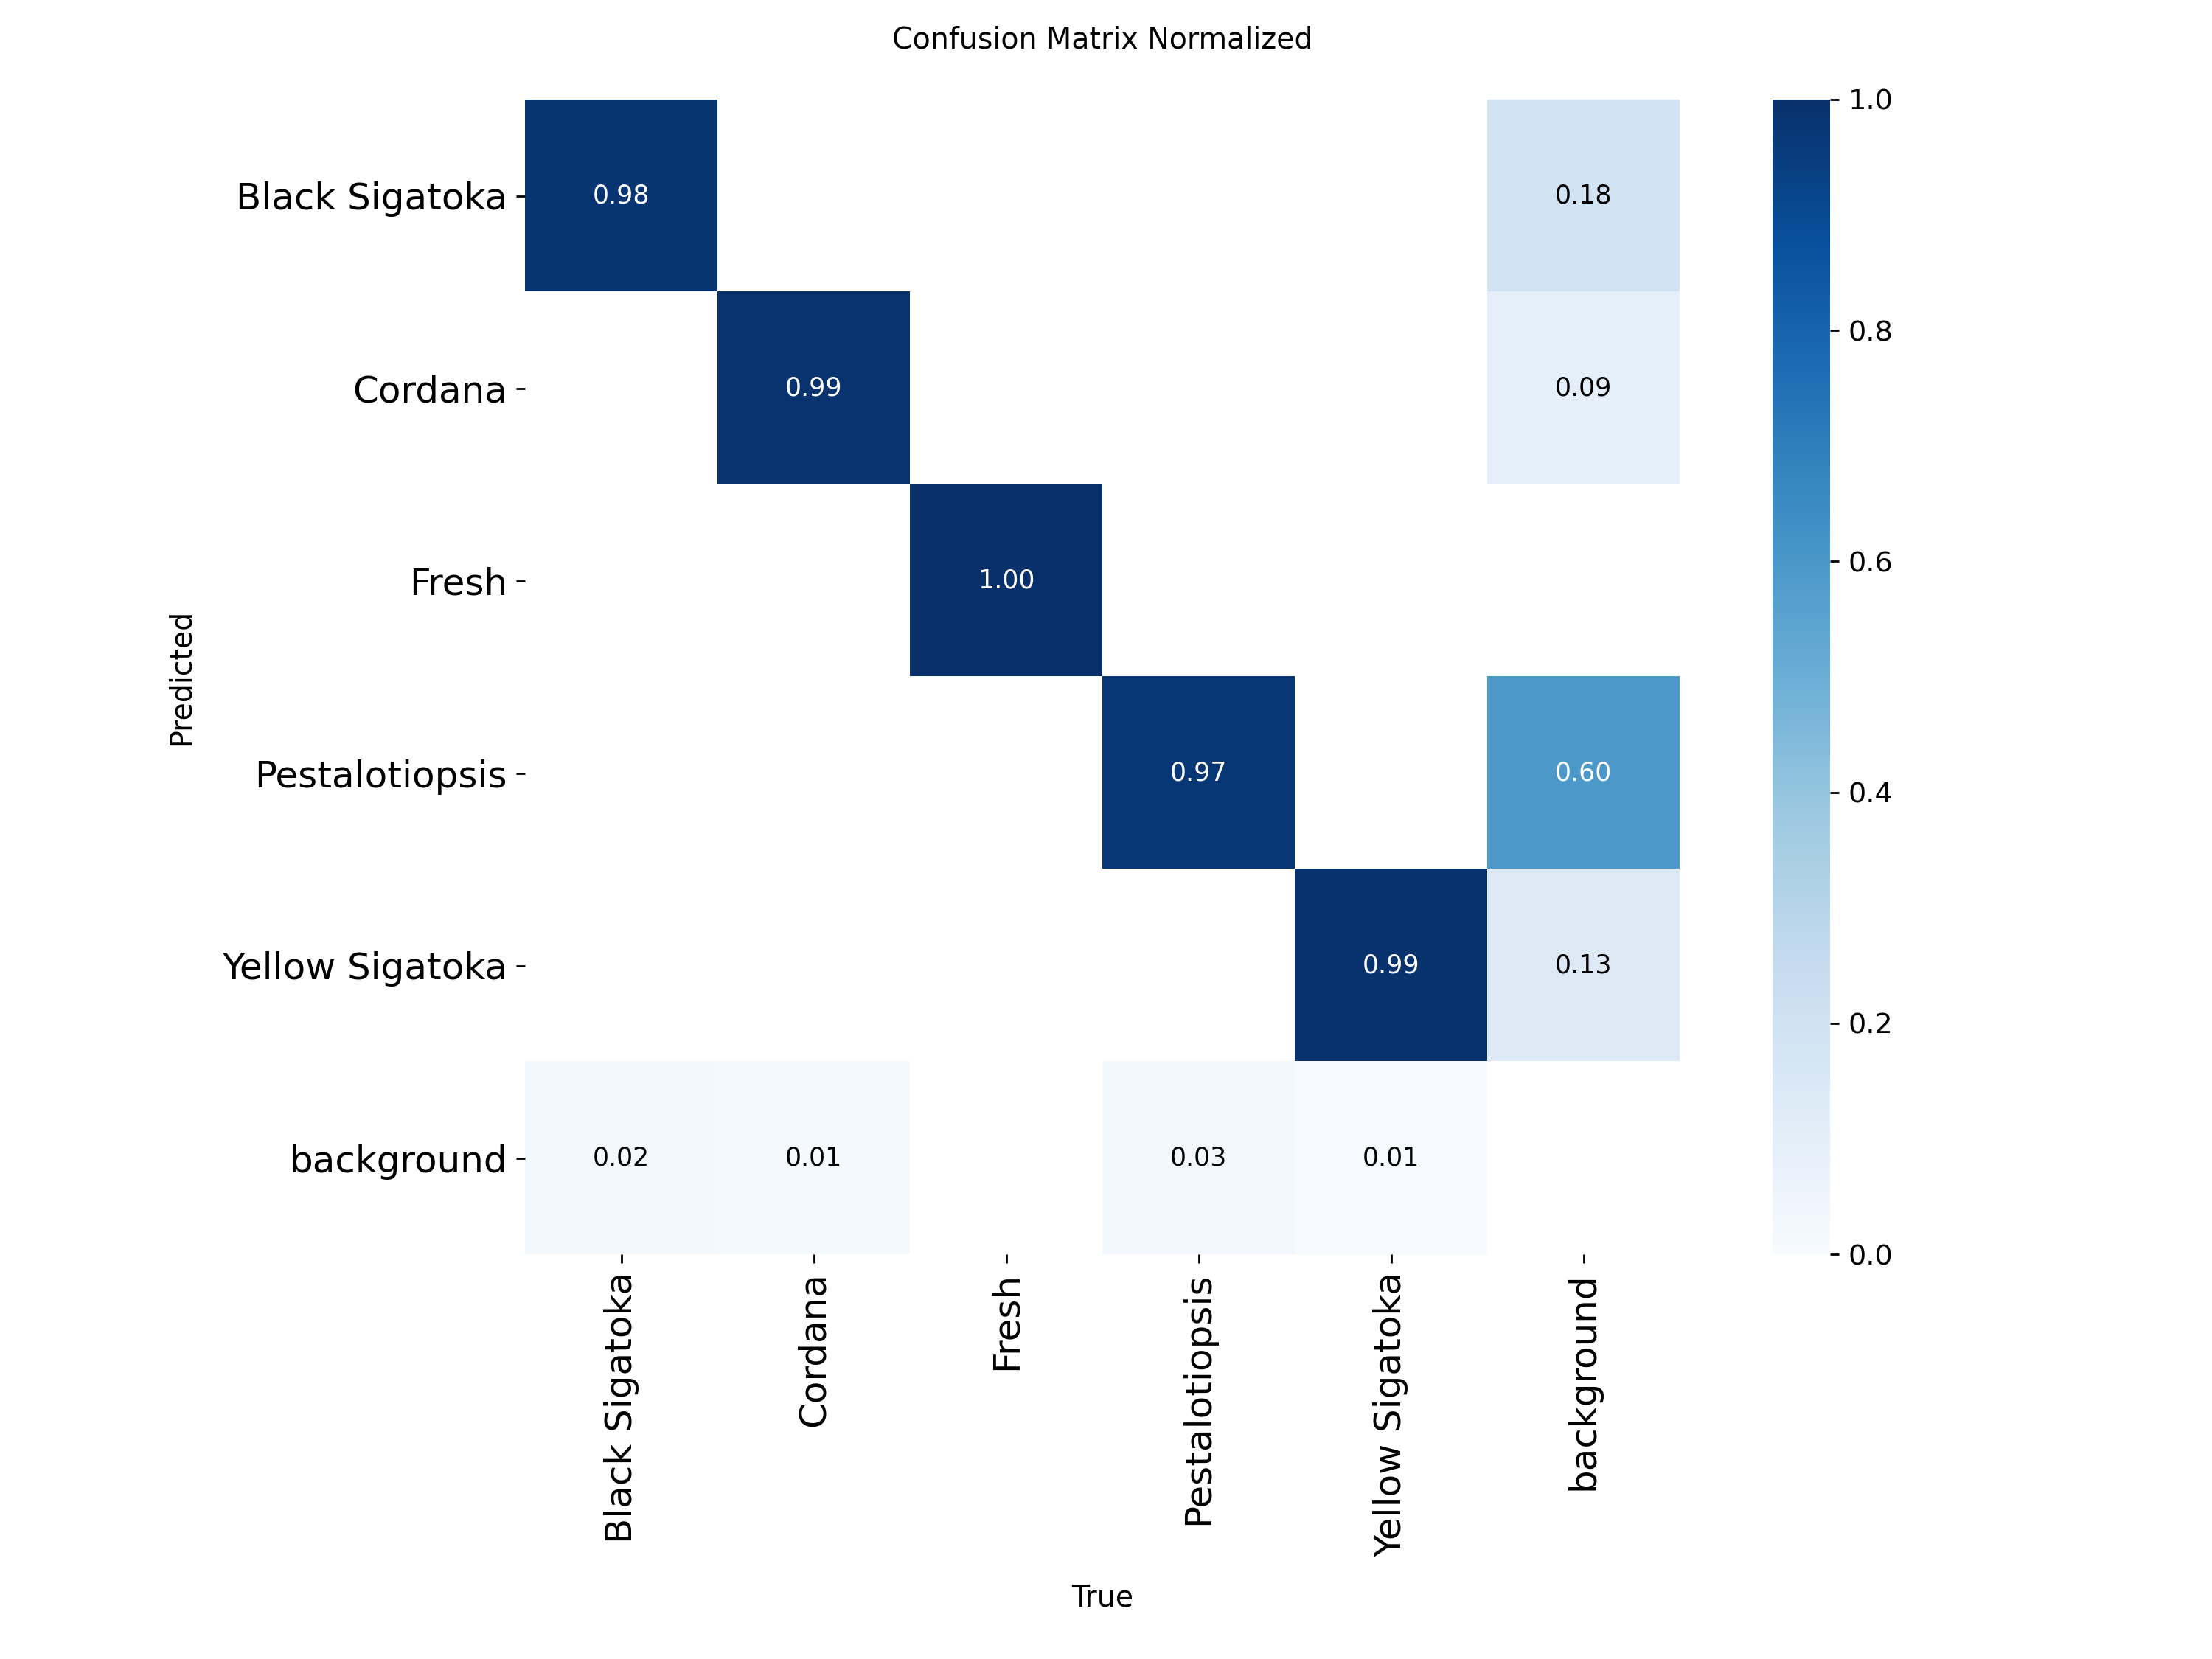


[!] Gambar PR_curve.png tidak ditemukan.

👉 3. GRAFIK LOSS & TRAINING RESULTS


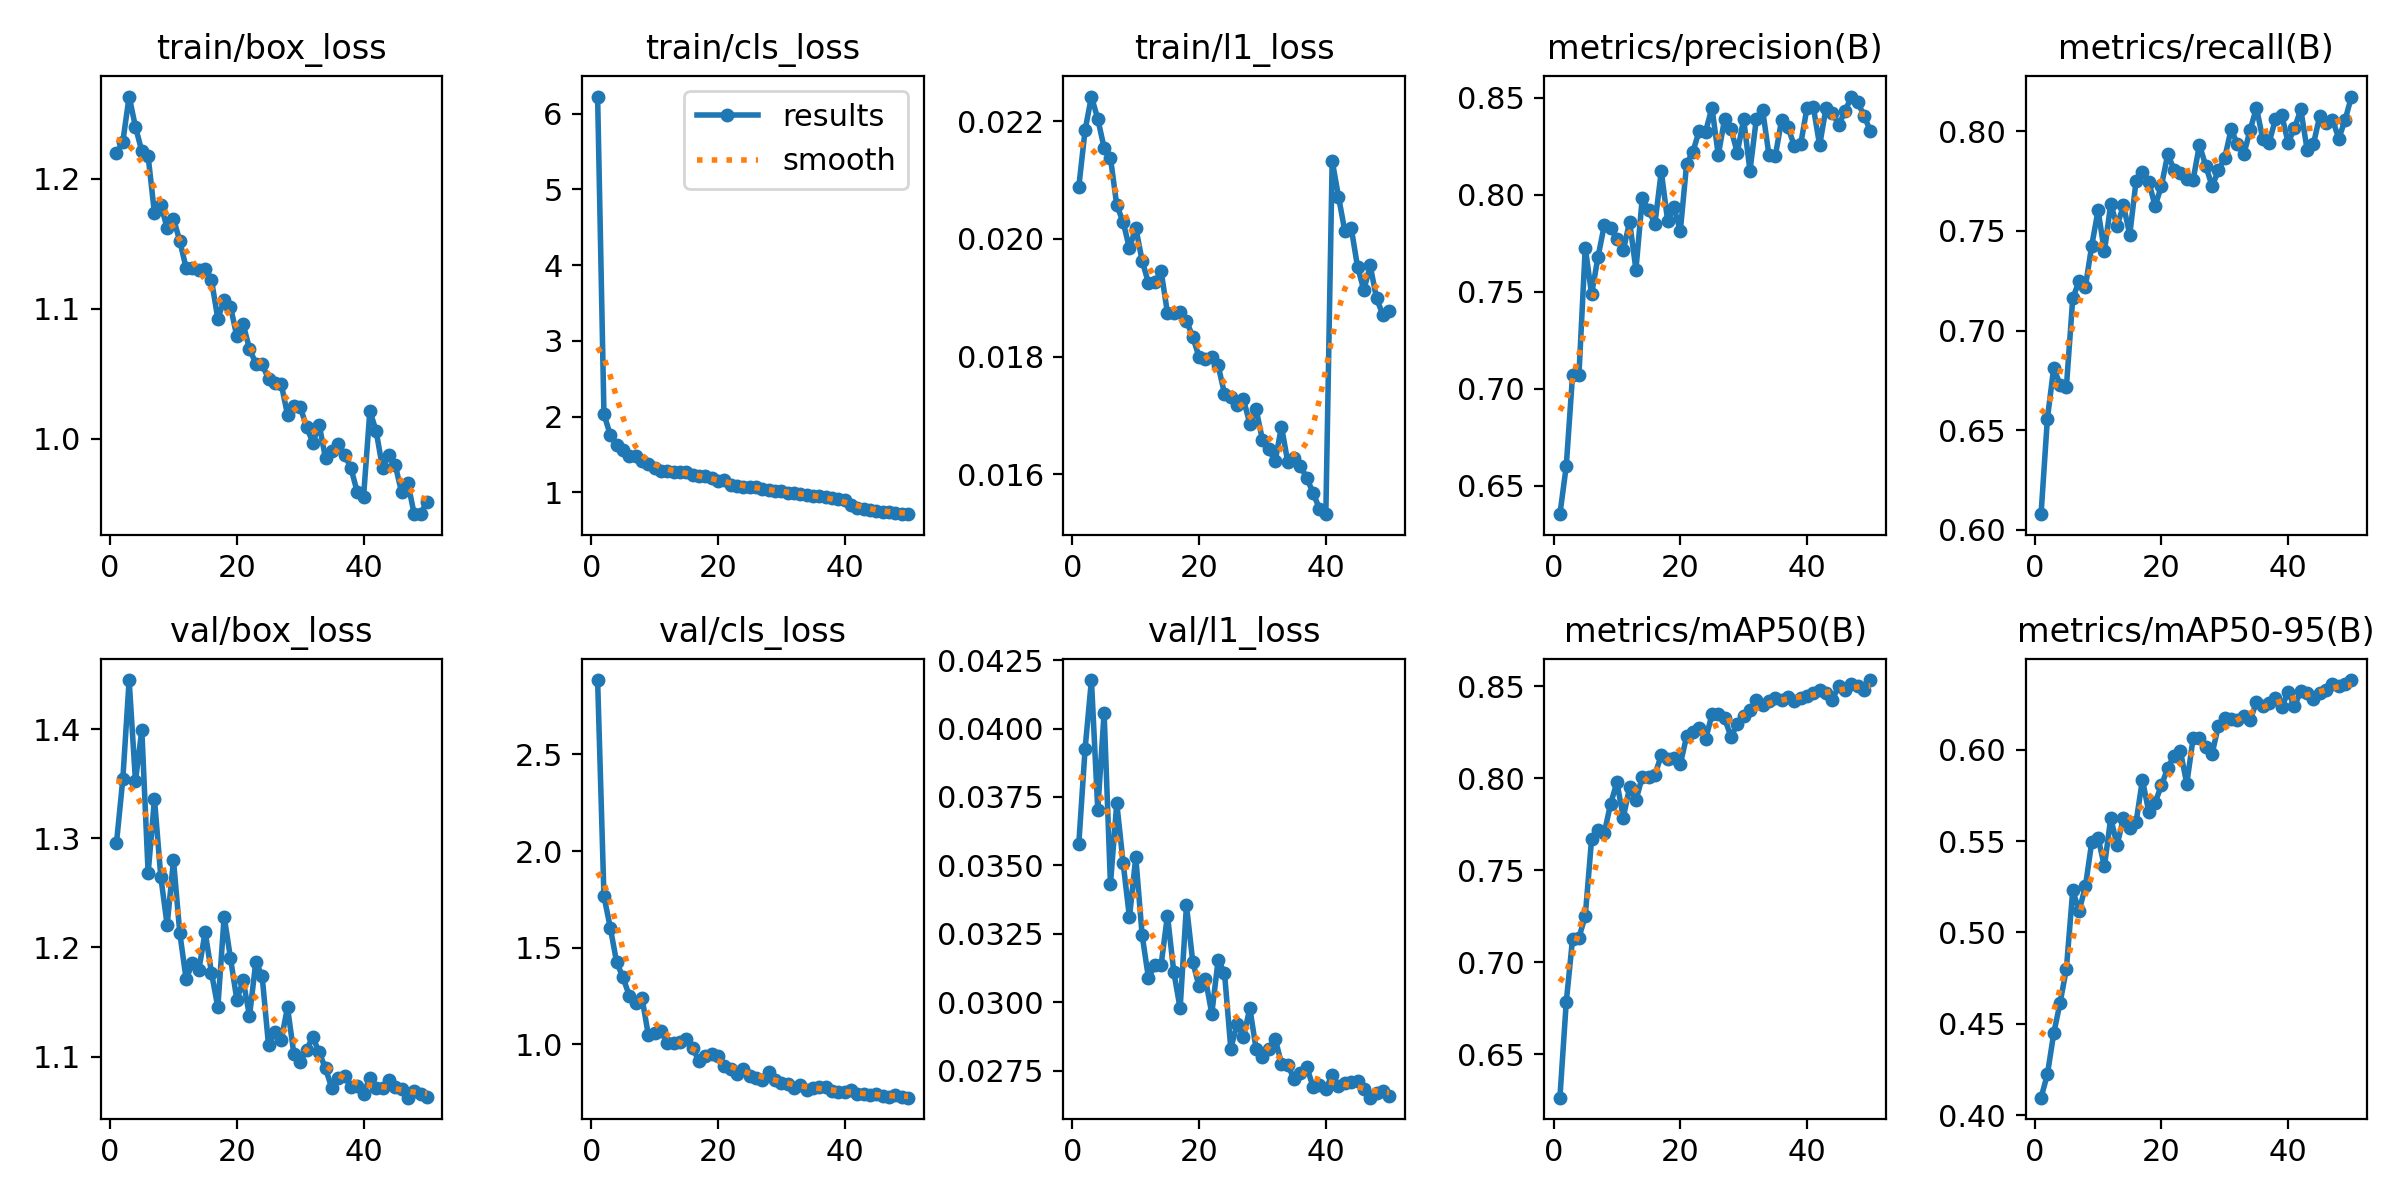


[INFO] Mengukur rata-rata Latensi Inferensi di CPU (Kaggle Intel Xeon)...
⏱️ Rata-rata Latensi Inferensi (CPU Only): 92.63 ms per gambar.


'/kaggle/working/best_yolo26n_clahe.pt'

In [6]:
# ==============================================================================
# TAHAP 4: EVALUASI METRIK, CSV, DAN MENAMPILKAN GAMBAR HASIL
# ==============================================================================
print("="*70)
print("📊 TAHAP 4: HASIL EVALUASI UJI DAN ANALISIS VISUAL")
print("="*70)

sum_rows, cls_rows = [], []

# 1. Menghitung Metrik
print("[PROSES] Mengekstraksi metrik pada data TEST...")
for name, best_pt in trained_models.items():
    yaml_path = str(DIR_CLAHE/'data.yaml') if 'CLAHE' in name else str(DIR_RAW/'data.yaml')
    metrics = YOLO(best_pt).val(data=yaml_path, split='test', imgsz=640, plots=True, verbose=False)
    
    sum_rows.append({
        'Skenario Arsitektur': name, 
        'Precision (%)': round(metrics.box.mp * 100, 2),
        'Recall (%)': round(metrics.box.mr * 100, 2),
        'mAP@50 (%)': round(metrics.box.map50 * 100, 2),
        'mAP@50-95 (%)': round(metrics.box.map * 100, 2)
    })
    
    if name == '4_YOLO26n_LAB_CLAHE':
        for i, cls in enumerate(CLASS_NAMES):
            p, r, ap50, _ = metrics.box.class_result(i)
            cls_rows.append({
                'Kelas Penyakit': cls, 
                'Precision (%)': round(p*100, 2), 
                'Recall (%)': round(r*100, 2),
                'AP@50 (%)': round(ap50*100, 2)
            })

df_sum = pd.DataFrame(sum_rows)
df_cls = pd.DataFrame(cls_rows)

df_sum.to_csv('/kaggle/working/tabel_komparasi.csv', index=False)
df_cls.to_csv('/kaggle/working/tabel_ap_kelas.csv', index=False)

print("\n📌 TABEL 1: PERBANDINGAN GLOBAL ANTAR-ARSITEKTUR & ABLASI CLAHE")
display(df_sum)

print("\n📌 TABEL 2: RINCIAN AP PER KELAS PADA MODEL TERBAIK (Membuktikan kesulitan lokalisasi Pestalotiopsis)")
display(df_cls)

# 2. Menampilkan Gambar Hasil Otomatis (Confusion Matrix)
run_dir = Path(f"/kaggle/working/runs/4_YOLO26n_LAB_CLAHE")

images_to_show = {
    "1. CONFUSION MATRIX (Bukti Kemiripan Visual Black vs Yellow Sigatoka)": "confusion_matrix_normalized.png",
    "2. PRECISION-RECALL CURVE": "PR_curve.png",
    "3. GRAFIK LOSS & TRAINING RESULTS": "results.png"
}

print("\n" + "="*70)
print("🖼️ MENAMPILKAN GAMBAR HASIL EVALUASI (YOLO26n + LAB-CLAHE)")
print("="*70)

for title, filename in images_to_show.items():
    img_path = run_dir / filename
    if not img_path.exists():
        img_path = run_dir / filename.replace("_normalized", "") 
        
    if img_path.exists():
        print(f"\n👉 {title}")
        display(Image(filename=str(img_path), width=850))
    else:
        print(f"\n[!] Gambar {filename} tidak ditemukan.")

# 3. Benchmark Latensi CPU Dummy Run untuk Konteks
print("\n[INFO] Mengukur rata-rata Latensi Inferensi di CPU (Kaggle Intel Xeon)...")
dummy_model = YOLO(trained_models['4_YOLO26n_LAB_CLAHE'])
sample_imgs = list((DIR_CLAHE / 'test' / 'images').glob('*.*'))[:20]
t_infer = []
for p in sample_imgs:
    t0 = time.perf_counter()
    _ = dummy_model.predict(str(p), imgsz=640, device='cpu', verbose=False)
    t_infer.append((time.perf_counter() - t0) * 1000)
    
print(f"⏱️ Rata-rata Latensi Inferensi (CPU Only): {np.mean(t_infer):.2f} ms per gambar.")

shutil.copyfile(trained_models['4_YOLO26n_LAB_CLAHE'], '/kaggle/working/best_yolo26n_clahe.pt')

---
### TAHAP 5: Unduhan (Base64 ZIP)
Membuat satu paket `.zip` berisi bobot model `.pt`, file data `.csv`, dan gambar evaluasi, lalu menyediakan tombol unduh langsung (*Direct HTML Download*) agar terhindar dari *Error 404 Kaggle*.

In [7]:
# ==============================================================================
# TAHAP 5: ZIP COMPRESSION & GENERATE ROBUST HTML DOWNLOAD LINK
# ==============================================================================
import base64
import zipfile
from IPython.display import HTML, display

ZIP_NAME = "MusaVision_Sidang_Data"
ZIP_PATH = f"/kaggle/working/{ZIP_NAME}.zip"

print("\n" + "="*70)
print("📥 TAHAP 5: MENYIAPKAN FILE DOWNLOAD UNTUK MAHASISWA")
print("="*70)

print("[PROSES] Mengompres seluruh folder runs dan file CSV ke dalam ZIP...")
shutil.make_archive(f"/kaggle/working/{ZIP_NAME}", 'zip', '/kaggle/working/runs')

with zipfile.ZipFile(ZIP_PATH, 'a') as zipf:
    for f in ['best_yolo26n_clahe.pt', 'tabel_komparasi.csv', 'tabel_ap_kelas.csv']:
        if os.path.exists(f'/kaggle/working/{f}'):
            zipf.write(f'/kaggle/working/{f}', arcname=f)

print("[SUKSES] File ZIP berhasil dibuat! Silakan klik tombol hijau di bawah.")

download_html = f"""
<div style="padding: 20px; background-color: #f0fdf4; border: 2px solid #22c55e; border-radius: 10px; margin-top: 20px; text-align: center;">
    <h2 style="color: #166534; margin-top: 0;">🎉 Seluruh Hasil Skripsi Siap Diunduh!</h2>
    <p style="color: #15803d; font-size: 15px;">Semua Bobot (.pt), Tabel (.csv), dan Grafik Confusion Matrix sudah dibungkus aman.</p>
    <a href="javascript:void(0);" onclick="downloadFile('{ZIP_PATH}', '{ZIP_NAME}.zip')" 
       style="display: inline-block; padding: 15px 30px; background-color: #16a34a; color: white; text-decoration: none; font-weight: bold; border-radius: 8px; font-size: 18px; box-shadow: 0 4px 6px rgba(0,0,0,0.1);">
       ⬇️ KLIK DI SINI UNTUK DOWNLOAD .ZIP
    </a>
    <p style="color: #6b7280; font-size: 13px; margin-top: 20px;">
       <i>*Jika tombol di atas tidak bereaksi, buka Panel Kanan Kaggle -> <b>Output</b> -> <b>/kaggle/working</b> -> klik ikon <b>titik tiga</b> pada file <b>{ZIP_NAME}.zip</b> lalu pilih Download.</i>
    </p>
</div>

<script>
function downloadFile(filePath, fileName) {{
    const link = document.createElement('a');
    link.href = filePath.replace('/kaggle/working', '/kaggle/working/download'); 
    link.download = fileName;
    document.body.appendChild(link);
    link.click();
    document.body.removeChild(link);
}}
</script>
"""

display(HTML(download_html))


📥 TAHAP 5: MENYIAPKAN FILE DOWNLOAD UNTUK MAHASISWA
[PROSES] Mengompres seluruh folder runs dan file CSV ke dalam ZIP...
[SUKSES] File ZIP berhasil dibuat! Silakan klik tombol hijau di bawah.
